# 01 · Exploratory data analysis of causRCA

**Objective.** Describe the causRCA dataset and decide which recordings and variables are suitable for causal discovery, SCM fitting and root cause analysis (RCA).

**Questions**
1. Are the graph files and the fault metadata consistent with each other and with the dataset README?
2. What does the dataset contain: recordings, fault scenarios, ground-truth causes, variable types?
3. How are events published: frequencies, gaps, batched timestamps?
4. Which variables never change in normal operation, and which change during faults?
5. What do coarse sampling intervals lose (short binary pulses, ordering of changes)?
6. How do the annotated fault timestamps relate to the observed variable changes?

**Outputs.** Figures `results/figures/01_*.pdf|png`, tables `results/tables/01_*.csv`.

> Fault labels are used here only to describe the data. Later stages must not use them to select variables or to tune causal discovery.

In [15]:
%pip install -e ..

Obtaining file:///Users/shwetabambal/Desktop/thesis/causalAI-failure-prevention
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for causal-rca (pyproject.toml) ... done
  Created wheel for causal-rca: filename=causal_rca-0.1.0-0.editable-py3-none-any.whl size=5317 sha256=e3f7cfc053fcfed4286af815720c04172967c6c8066d490b9a37da60790e5c7a
  Stored in directory: /private/var/folders/pp/qhtyx8_n4b1b_fkkshd1qjp00000gn/T/pip-ephem-wheel-cache-0anabwme/wheels/06/3c/d4/44bda1ab10f933db306a60cd1e1e3c7b5bf7115eb00c690477
Successfully built causal-rca
  Attempting uninstall: causal-rca
    Found existing installation: causal-rca 0.1.0
    Uninstalling causal-rca-0.1.0:
      Successfully uninstalled causal-rca-0.1.0

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade 

In [16]:
import causal_rca; 
print(causal_rca.__file__)

/Users/shwetabambal/Desktop/thesis/causalAI-failure-prevention/src/causal_rca/__init__.py


In [17]:
from dataclasses import asdict

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.ticker import NullFormatter, PercentFormatter

from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import preprocessing as pp

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)

# sampling intervals compared here; 0.5 s and 1 s are the candidates
INTERVALS = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
CANDIDATES = [0.5, 1.0]

## 1. Metadata consistency

We compare the expert-graph files (CSV vs GML), the subsystem graphs against the full graph, and the fault metadata against the counts in `README_DATASET.md`. Every later stage relies on these files, so any failed check must be understood before we continue.

In [18]:
# compare graph files and fault metadata with each other and with the readme
checks = data.check_metadata()
print(f'{checks.passed.sum()} of {len(checks)} checks passed')
ev.save_table(checks, '01_metadata_checks')
checks

50 of 51 checks passed


,scope,check,expected,observed,passed
0,full,nodes (csv),92,92,True
1,full,edges (csv),104,104,True
2,full,gml nodes equal csv nodes,True,True,True
3,full,gml edges equal csv edges,True,True,True
4,full,normal recordings,170,170,True
5,full,fault runs,100,100,True
6,full,scenarios,19,19,True
7,full,distinct diagnoses,10,10,True
8,full,distinct causing variables,14,14,True
9,full,runs with ordered causes.json timestamps,100,97,False


**Findings.** 50 of 51 checks pass. CSV and GML files agree, every subsystem graph is part of the full graph, and all README counts are reproduced (92/104, 15/10, 17/18, 11/15, 25/41/34 runs, 19 scenarios, 10 diagnoses, 14 causing variables). The one failure is 3 hydraulics runs whose `causes.json` timestamps are not in the expected order; section 7 shows why.

## 2. Dataset composition and ground truth

The true injected causes are the `manipulatedVars` of each experiment description. `causes.json` only holds timestamps. We keep root cause, diagnosis, expected state pattern and alarms apart.

In [19]:
# recordings, fault scenarios and fault runs
infos = pp.discover_recordings(data.RAW_DIR)
recordings = pd.DataFrame([asdict(r) for r in infos])
experiments = data.load_experiments()
runs = data.load_fault_runs()
ev.save_table(experiments, '01_experiments')

print(recordings.groupby(['source', 'subsystem'], dropna=False).size(), '\n')
experiments[['subsystem', 'experiment_id', 'n_runs', 'manipulated_vars', 'alarms', 'diagnosis_ids', 'diagnosis_names']]

source    subsystem 
dig_twin  coolant        25
          hydraulics     41
          probe          34
real_op   NaN           170
dtype: int64 



,subsystem,experiment_id,n_runs,manipulated_vars,alarms,diagnosis_ids,diagnosis_names
0,coolant,exp_22,6,"[HP_Pump_Ok, LT_Level_Ok]","[HP_A_700304, LT_A_700317]",[diag_9],[Leakage in coolant system.]
1,coolant,exp_27,7,"[CLT_Level_lt_Min, HP_Pump_Ok]","[CLT_A_700310, HP_A_700304]",[diag_9],[Leakage in coolant system.]
2,coolant,exp_28,6,"[CLF_Filter_Ok, F_Filter_Ok, LP_Pump_Ok]","[CLF_A_700307, F_A_700313, LP_A_700301]",[diag_10],[Highly Contaminated Coolant.]
3,coolant,exp_35,6,"[CLF_Filter_Ok, LP_Pump_Ok]","[CLF_A_700307, LP_A_700301]",[diag_10],[Highly Contaminated Coolant.]
4,hydraulics,exp_8,5,[Hyd_Pressure],[Hyd_A_700202],[diag_4],[Leakage in hydraulics system]
5,hydraulics,exp_9,5,[Hyd_Pressure],[Hyd_A_700202],[diag_5],[Hyd_Pressure Sensor is defective.]
6,hydraulics,exp_10,5,"[Hyd_Temp_lt_70, Hyd_Temp_lt_80]","[Hyd_A_700203, Hyd_A_700204]",[diag_6],[Hydraulic oil cooler defective.]
7,hydraulics,exp_12,5,[Hyd_Level_Ok],"[Hyd_A_700205, Hyd_A_700206]",[diag_4],[Leakage in hydraulics system]
8,hydraulics,exp_13,4,[Hyd_Pump_Ok],[Hyd_A_700208],[diag_7],[Hydraulic pump motor fails]
9,hydraulics,exp_14,4,"[Hyd_Level_Ok, Hyd_Pressure]","[Hyd_A_700202, Hyd_A_700205, Hyd_A_700206]",[diag_4],[Leakage in hydraulics system]


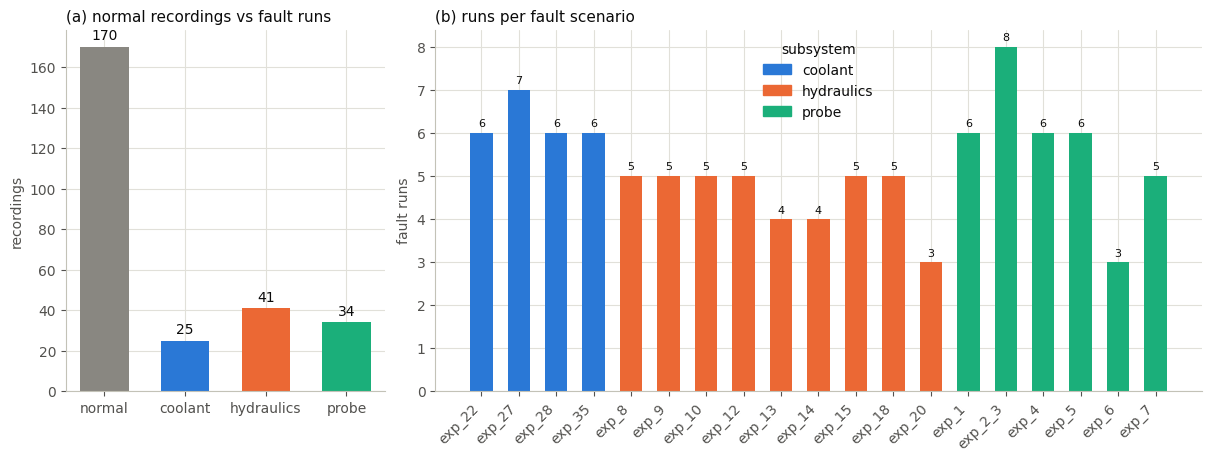

In [20]:
# figure 1: recordings per group and runs per fault scenario
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 2.4]}, layout='constrained')

groups = ['normal'] + list(data.SUBSYSTEMS)
counts = [int((recordings.source == 'real_op').sum())] + [int((recordings.subsystem == s).sum()) for s in data.SUBSYSTEMS]
colors = [ev.INK['muted']] + [ev.SUBSYSTEM_COLORS[s] for s in data.SUBSYSTEMS]
bars = ax_a.bar(groups, counts, color=colors, width=0.6)
ax_a.bar_label(bars, padding=3)
ax_a.set_ylabel('recordings')
ax_a.set_title('(a) normal recordings vs fault runs')

x = np.arange(len(experiments))
bars = ax_b.bar(x, experiments.n_runs, color=[ev.SUBSYSTEM_COLORS[s] for s in experiments.subsystem], width=0.6)
ax_b.bar_label(bars, padding=3, fontsize=8)
ax_b.set_xticks(x, experiments.experiment_id, rotation=45, ha='right')
ax_b.set_ylabel('fault runs')
ax_b.set_title('(b) runs per fault scenario')
handles = [plt.Rectangle((0, 0), 1, 1, color=ev.SUBSYSTEM_COLORS[s]) for s in data.SUBSYSTEMS]
ax_b.legend(handles, data.SUBSYSTEMS, title='subsystem')

ev.save_figure(fig, '01_dataset_composition')
plt.show()

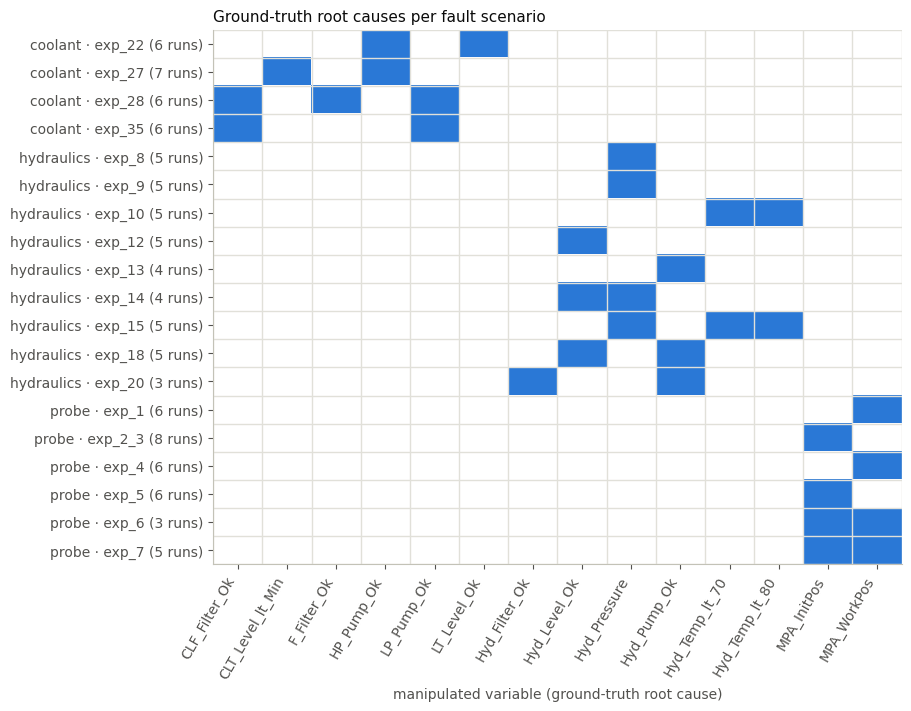

multi-cause scenarios: 11 of 19
scenarios with more than one diagnosis: 2


In [21]:
# figure 2: which variables are manipulated in which scenario (ground truth)
cause_order = (
    experiments.explode('manipulated_vars')[['subsystem', 'manipulated_vars']]
    .drop_duplicates()
    .sort_values(['subsystem', 'manipulated_vars'])['manipulated_vars']
    .tolist()
)
matrix = np.array([[v in vs for v in cause_order] for vs in experiments.manipulated_vars], dtype=float)
row_labels = [f'{s} · {e} ({n} runs)' for s, e, n in zip(experiments.subsystem, experiments.experiment_id, experiments.n_runs)]

fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
ax.imshow(matrix, cmap=ListedColormap([ev.INK['surface'], ev.COLORS[0]]), aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(cause_order)), cause_order, rotation=60, ha='right')
ax.set_yticks(range(len(row_labels)), row_labels)
# thin lines between cells
ax.grid(False)
ax.set_xticks(np.arange(-0.5, len(cause_order)), minor=True)
ax.set_yticks(np.arange(-0.5, len(row_labels)), minor=True)
ax.grid(which='minor', color=ev.INK['grid'], linewidth=1)
ax.tick_params(which='minor', length=0)
ax.set_xlabel('manipulated variable (ground-truth root cause)')
ax.set_title('Ground-truth root causes per fault scenario')
ev.save_figure(fig, '01_ground_truth_matrix')
plt.show()

print('multi-cause scenarios:', int(experiments.multi_cause.sum()), 'of', len(experiments))
print('scenarios with more than one diagnosis:', int(experiments.multi_diagnosis.sum()))

In [22]:
# root-cause variables that appear in more than one scenario
shared = experiments.explode('manipulated_vars').groupby('manipulated_vars').experiment_id.apply(list)
shared[shared.str.len() > 1]

manipulated_vars
CLF_Filter_Ok                   [exp_28, exp_35]
HP_Pump_Ok                      [exp_22, exp_27]
Hyd_Level_Ok            [exp_12, exp_14, exp_18]
Hyd_Pressure      [exp_8, exp_9, exp_14, exp_15]
Hyd_Pump_Ok             [exp_13, exp_18, exp_20]
Hyd_Temp_lt_70                  [exp_10, exp_15]
Hyd_Temp_lt_80                  [exp_10, exp_15]
LP_Pump_Ok                      [exp_28, exp_35]
MPA_InitPos       [exp_2_3, exp_5, exp_6, exp_7]
MPA_WorkPos         [exp_1, exp_4, exp_6, exp_7]
Name: experiment_id, dtype: object

In [23]:
# root cause is not the same as diagnosis: compare causes, diagnoses and expected states
experiments[['experiment_id', 'manipulated_vars', 'diagnosis_ids', 'expected_states', 'instead_failure']]

,experiment_id,manipulated_vars,diagnosis_ids,expected_states,instead_failure
0,exp_22,"[HP_Pump_Ok, LT_Level_Ok]",[diag_9],"{'diag_9': {'HP_Pump_Ok': False, 'LT_Level_Ok'...",The high pressure pump fails and coolant level...
1,exp_27,"[CLT_Level_lt_Min, HP_Pump_Ok]",[diag_9],"{'diag_9': {'CLT_Level_lt_Min': True, 'HP_Pump...","Defective or worn seals cause coolant to leak,..."
2,exp_28,"[CLF_Filter_Ok, F_Filter_Ok, LP_Pump_Ok]",[diag_10],"{'diag_10': {'CLF_Filter_Ok': False, 'F_Filter...","Due to highly contaminated coolant, the Hydac ..."
3,exp_35,"[CLF_Filter_Ok, LP_Pump_Ok]",[diag_10],"{'diag_10': {'CLF_Filter_Ok': False, 'LP_Pump_...","As debris accumulates, the Hydac filter become..."
4,exp_8,[Hyd_Pressure],[diag_4],{'diag_4': {'Hyd_Pressure': 6600}},A leak causes hydraulic pressure to fall conti...
5,exp_9,[Hyd_Pressure],[diag_5],{'diag_5': {'Hyd_Pressure': '!=10000'}},The defective pressure‑level sensor outputs ra...
6,exp_10,"[Hyd_Temp_lt_70, Hyd_Temp_lt_80]",[diag_6],"{'diag_6': {'Hyd_Temp_lt_70': True, 'Hyd_Temp_...","Due to a defective cooler, oil temperature ris..."
7,exp_12,[Hyd_Level_Ok],[diag_4],{'diag_4': {'Hyd_Level_Ok': False}},"Oil level falls continuously due to a leak, ev..."
8,exp_13,[Hyd_Pump_Ok],[diag_7],{'diag_7': {'Hyd_Pump_Ok': False}},The hydraulic pump motor fails spontaneously d...
9,exp_14,"[Hyd_Level_Ok, Hyd_Pressure]",[diag_4],"{'diag_4': {'Hyd_Pressure': '!=10000', 'Hyd_Le...","A hydraulic leak develops. First, a warning fo..."


**Findings.**
- 19 scenarios; **11** have more than one manipulated variable (all 4 coolant scenarios, 5 of 9 hydraulics, 2 of 6 probe). RCA must rank several true causes per run, so Hit@3 and MAP@3 are needed besides Top-1.
- 10 of the 14 cause variables appear in more than one scenario (`Hyd_Pressure`, `MPA_InitPos` and `MPA_WorkPos` in four each). A method that memorises scenario → cause could score well without causal reasoning, so RCA must never be tuned on the scenarios it is tested on.
- Same cause, different diagnosis: exp_8 and exp_9 both manipulate `Hyd_Pressure` (leak, diag_4, vs defective sensor, diag_5). Root-cause variable and diagnosis are different targets; we evaluate the variable.
- Only 2 scenarios carry two diagnoses (exp_15, exp_18).
- `expected_states` lists variables that were not manipulated (e.g. `MPA_toInitPos`). They describe the symptom pattern, not causes.
- *Thesis note:* probe exp_1/exp_4 and exp_2_3/exp_5 share causes but differ in failure mode (stuck false vs stuck true). Worth one sentence in the dataset chapter.

## 3. Load and parse all events

We reuse the tested preprocessing functions: every recording is loaded separately, values are parsed by their declared type, duplicates follow the last-row-wins policy, and each event is marked as initial value, change or repeat.

In [24]:
# parse all 270 recordings in memory (about 10 s)
events = pp.parse_values(pp.load_all_events(infos, data.RAW_DIR))
events, duplicate_log = pp.resolve_duplicates(events)
events = pp.mark_changes(events)
stats = pp.event_statistics(events)
types = pp.node_types(events)

print(f'{len(events):,} events in {events.recording_id.nunique()} recordings, {len(duplicate_log)} duplicate events')
events.head()

508,466 events in 270 recordings, 0 duplicate events


,recording_id,source,subsystem,experiment_id,run_id,source_file,event_seq,time_s,time_s_raw,node,type,raw_value,value_num,value_cat,is_initial,is_change,is_repeat
0,coolant_exp_22_run_1,dig_twin,coolant,exp_22,run_1,dig_twin/exp_coolant/exp_22/run_1/faultDataset...,0,0.0,0.0,CBC_Closed,Binary,True,1.0,<NA>,True,False,False
1,coolant_exp_22_run_1,dig_twin,coolant,exp_22,run_1,dig_twin/exp_coolant/exp_22/run_1/faultDataset...,1,0.0,0.0,CBC_close,Binary,True,1.0,<NA>,True,False,False
2,coolant_exp_22_run_1,dig_twin,coolant,exp_22,run_1,dig_twin/exp_coolant/exp_22/run_1/faultDataset...,2,0.0,0.0,CBC_isOpen,Binary,False,0.0,<NA>,True,False,False
3,coolant_exp_22_run_1,dig_twin,coolant,exp_22,run_1,dig_twin/exp_coolant/exp_22/run_1/faultDataset...,3,0.0,0.0,CBC_open,Binary,False,0.0,<NA>,True,False,False
4,coolant_exp_22_run_1,dig_twin,coolant,exp_22,run_1,dig_twin/exp_coolant/exp_22/run_1/faultDataset...,4,0.0,0.0,ExU_On,Binary,False,0.0,<NA>,True,False,False


## 4. Variable types per subsystem

The declared type in the event data decides which statistical tests and mechanisms are valid later. ParCorr, for example, assumes continuous, linearly related variables.

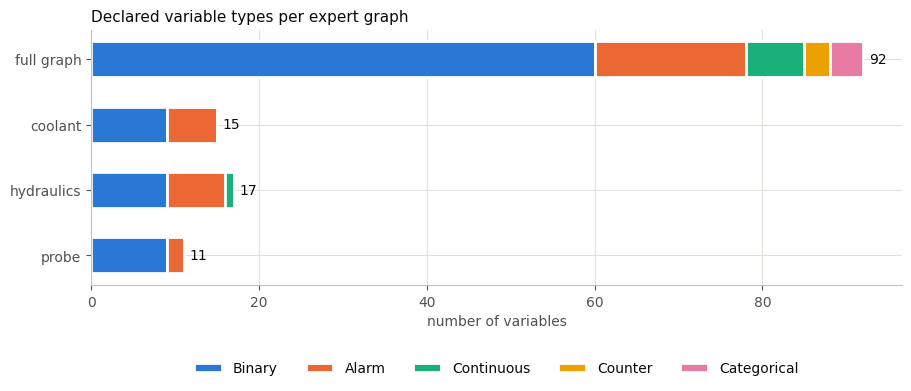

,Binary,Alarm,Continuous,Counter,Categorical
full graph,60,18,7,3,4
coolant,9,6,0,0,0
hydraulics,9,7,1,0,0
probe,9,2,0,0,0


In [25]:
# expert graphs of the full machine and the three subsystems
full_graph = data.load_expert_graph()
graphs = {s: data.load_expert_graph(subsystem=s) for s in data.SUBSYSTEMS}

# figure 3: declared variable types (from the event data) per graph
groups = {'full graph': list(full_graph.nodes), **{s: list(g.nodes) for s, g in graphs.items()}}
type_counts = pd.DataFrame(
    {name: pd.Series([types.get(n, 'not recorded') for n in nodes]).value_counts() for name, nodes in groups.items()}
).T.fillna(0).astype(int)
order = [t for t in pp.VARIABLE_TYPES if t in type_counts.columns] + [c for c in type_counts.columns if c not in pp.VARIABLE_TYPES]
type_counts = type_counts[order]

fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
left = np.zeros(len(type_counts))
for t in type_counts.columns:
    values = type_counts[t].to_numpy()
    ax.barh(type_counts.index, values, left=left, height=0.55, color=ev.TYPE_COLORS.get(t, ev.INK['muted']),
            edgecolor=ev.INK['surface'], linewidth=2, label=t)
    left += values
ax.bar_label(ax.containers[-1], labels=[str(int(v)) for v in left], padding=4)
ax.invert_yaxis()
ax.set_xlabel('number of variables')
ax.set_title('Declared variable types per expert graph')
ax.legend(ncol=len(type_counts.columns), loc='upper center', bbox_to_anchor=(0.5, -0.25))
ev.save_figure(fig, '01_variable_types')
plt.show()
type_counts

**Findings.**
- Coolant: 9 Binary + 6 Alarm, no continuous variable. Hydraulics: 9 Binary, 7 Alarm, 1 Continuous (`Hyd_Pressure`). Probe: 9 Binary + 2 Alarm.
- Of the full graph's 7 continuous variables, only `Hyd_Pressure` belongs to a subsystem. The other 6, and all 3 counters and 4 categoricals, are spindle and NC-program variables.
- Inside the subsystems a continuous-only ParCorr experiment is impossible (coolant, probe) or trivial (one variable in hydraulics). Stage 2 needs a conditional independence test for discrete data.

## 5. Event frequencies and constant variables

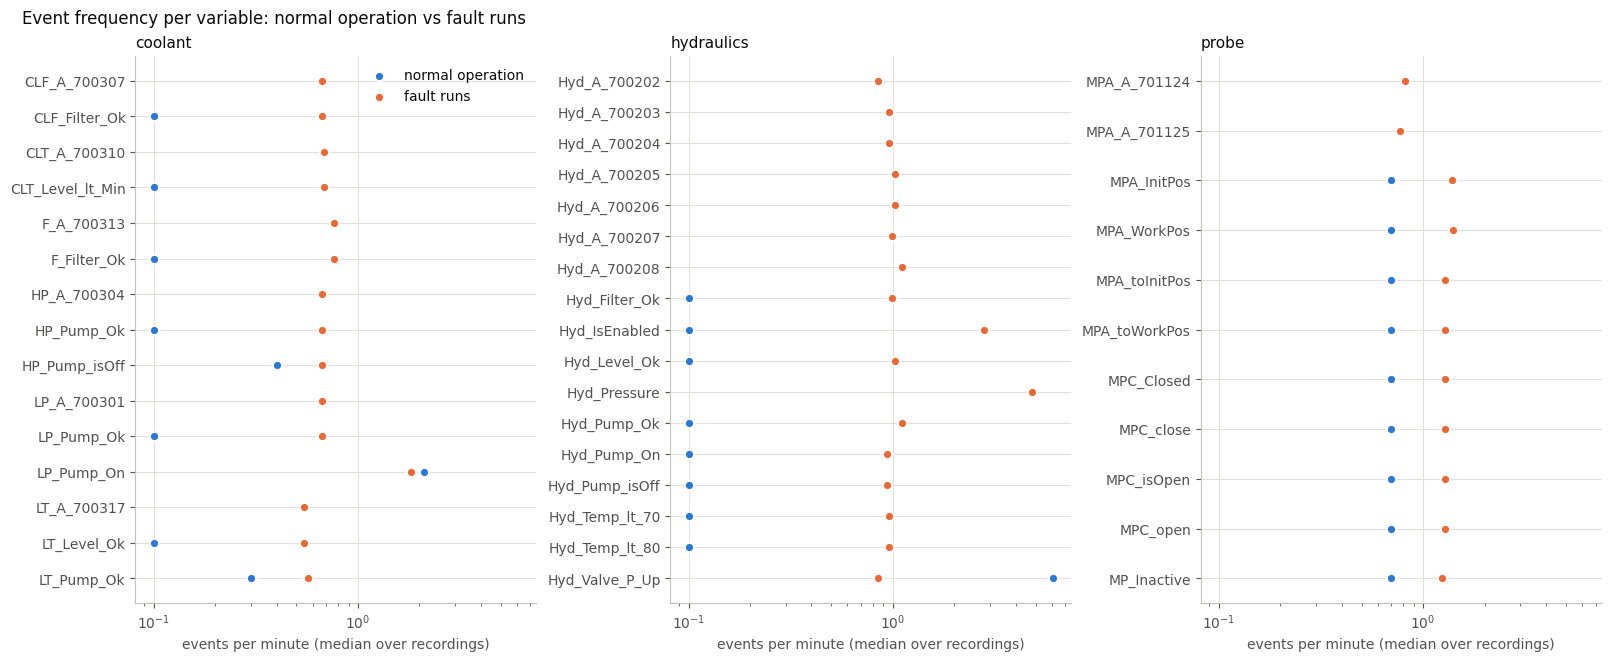

In [26]:
# figure 4: events per minute for every subsystem variable, normal vs fault runs
durations = events.groupby('recording_id').time_s.max().rename('duration_s')
rates = stats.join(durations, on='recording_id')
rates['events_per_min'] = rates.n_events / (rates.duration_s / 60)

fig, axes = plt.subplots(1, 3, figsize=(16, 6.5), sharex=True, layout='constrained')
for ax, (subsystem, graph) in zip(axes, graphs.items()):
    nodes = sorted(graph.nodes)
    y = np.arange(len(nodes))
    normal = rates[(rates.source == 'real_op') & rates.node.isin(nodes)].groupby('node').events_per_min.median()
    fault = rates[(rates.source == 'dig_twin') & (rates.subsystem == subsystem) & rates.node.isin(nodes)].groupby('node').events_per_min.median()
    for source, values in (('real_op', normal), ('dig_twin', fault)):
        ax.scatter(values.reindex(nodes), y, s=45, color=ev.SOURCE_COLORS[source], edgecolor=ev.INK['surface'],
                   linewidth=1.5, label=ev.SOURCE_LABELS[source], zorder=3)
    ax.set_yticks(y, nodes)
    ax.invert_yaxis()
    ax.set_xscale('log')
    ax.set_xlabel('events per minute (median over recordings)')
    ax.set_title(subsystem)
axes[0].legend(loc='best')
fig.suptitle('Event frequency per variable: normal operation vs fault runs', x=0.01, ha='left')
ev.save_figure(fig, '01_event_frequency')
plt.show()

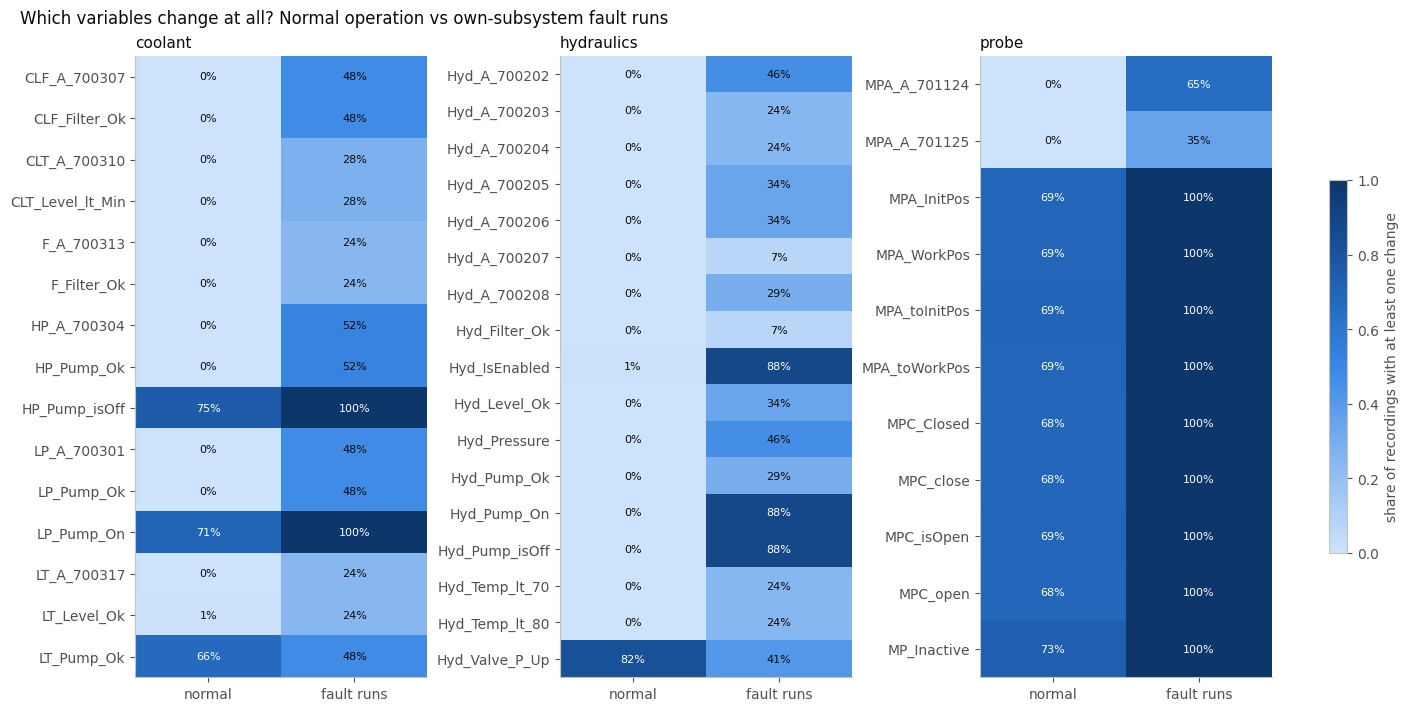

In [27]:
# figure 5: share of recordings in which each subsystem variable changes at least once
suitability = data.variable_suitability(stats, experiments, graphs)
ev.save_table(suitability, '01_variable_suitability')

fig, axes = plt.subplots(1, 3, figsize=(14, 7), layout='constrained')
for ax, subsystem in zip(axes, data.SUBSYSTEMS):
    table = suitability[suitability.subsystem == subsystem].set_index('variable')
    values = table[['normal_share_changing', 'fault_share_changing']].to_numpy(dtype=float)
    image = ax.imshow(values, cmap=ev.sequential_cmap(), vmin=0, vmax=1, aspect='auto')
    for (i, j), v in np.ndenumerate(values):
        ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8,
                color=ev.INK['surface'] if v > 0.55 else ev.INK['primary'])
    ax.set_xticks([0, 1], ['normal', 'fault runs'])
    ax.set_yticks(range(len(table)), table.index)
    ax.grid(False)
    ax.set_title(subsystem)
fig.colorbar(image, ax=axes, shrink=0.6, label='share of recordings with at least one change')
fig.suptitle('Which variables change at all? Normal operation vs own-subsystem fault runs', x=0.01, ha='left')
ev.save_figure(fig, '01_variable_change_share')
plt.show()

In [28]:
# number of variables per subsystem by where they vary
flags = ['varies_in_normal', 'varies_in_faults', 'usable_with_fault_runs', 'is_alarm', 'is_ground_truth_cause']
summary = suitability.groupby('subsystem')[flags].sum()
summary.insert(0, 'n_variables', suitability.groupby('subsystem').size())
summary

,n_variables,varies_in_normal,varies_in_faults,usable_with_fault_runs,is_alarm,is_ground_truth_cause
subsystem,,,,,,
coolant,15,4,15,15,6,6
hydraulics,17,2,17,17,7,6
probe,11,9,11,11,2,2


In [29]:
# ground-truth causes: do they vary in normal operation at all?
suitability.loc[suitability.is_ground_truth_cause,
                ['subsystem', 'variable', 'declared_type', 'normal_share_changing', 'fault_share_changing']]

,subsystem,variable,declared_type,normal_share_changing,fault_share_changing
1,coolant,CLF_Filter_Ok,Binary,0.000000,0.480000
3,coolant,CLT_Level_lt_Min,Binary,0.000000,0.280000
5,coolant,F_Filter_Ok,Binary,0.000000,0.240000
7,coolant,HP_Pump_Ok,Binary,0.000000,0.520000
10,coolant,LP_Pump_Ok,Binary,0.000000,0.480000
13,coolant,LT_Level_Ok,Binary,0.005882,0.240000
22,hydraulics,Hyd_Filter_Ok,Binary,0.000000,0.073171
24,hydraulics,Hyd_Level_Ok,Binary,0.000000,0.341463
25,hydraulics,Hyd_Pressure,Continuous,0.000000,0.463415
26,hydraulics,Hyd_Pump_Ok,Binary,0.000000,0.292683


**Findings.**
- Coolant: only **4 of 15** variables ever change in normal operation (`HP_Pump_isOff` 75%, `LP_Pump_On` 71%, `LT_Pump_Ok` 66% of recordings; `LT_Level_Ok` in 1 of 170). Hydraulics: **2 of 17** (`Hyd_Valve_P_Up` 82%, `Hyd_IsEnabled` in 1 recording). Probe: **9 of 11** (about 69%); only its two alarms stay constant.
- None of the 15 subsystem alarms ever fires in normal operation. Alarms outside the subsystems do (`T_A_701309` in 149 of 170 normal recordings, `SR_A_67040` in 20, `Prog_A_701330` in 2).
- 11 of the 12 coolant and hydraulics root-cause variables never change in normal operation. The probe causes (`MPA_InitPos`, `MPA_WorkPos`) change in 69% of normal recordings, as part of normal machining.
- Every subsystem variable changes in at least one fault run of its own subsystem, so all of them are usable once fault runs are included.
- Consequence for Stage 2: discovery on normal data alone cannot find edges that start at coolant or hydraulics fault variables, because a constant variable carries no information. Discovery must include fault runs.
- *Thesis note:* fault runs are interventional data, since the digital twin forces the manipulated variables. Pooling runs from different scenarios mixes causal regimes, while PCMCI+ assumes one stationary mechanism. This pooling is a methodological decision we must justify in Stage 2.

## 6. Sampling behaviour

OPC UA publishes a value when it changes. Timestamps are publish times, so several variables often share one timestamp. We look at gaps between events, batched timestamps, and what a regular grid of each interval keeps.

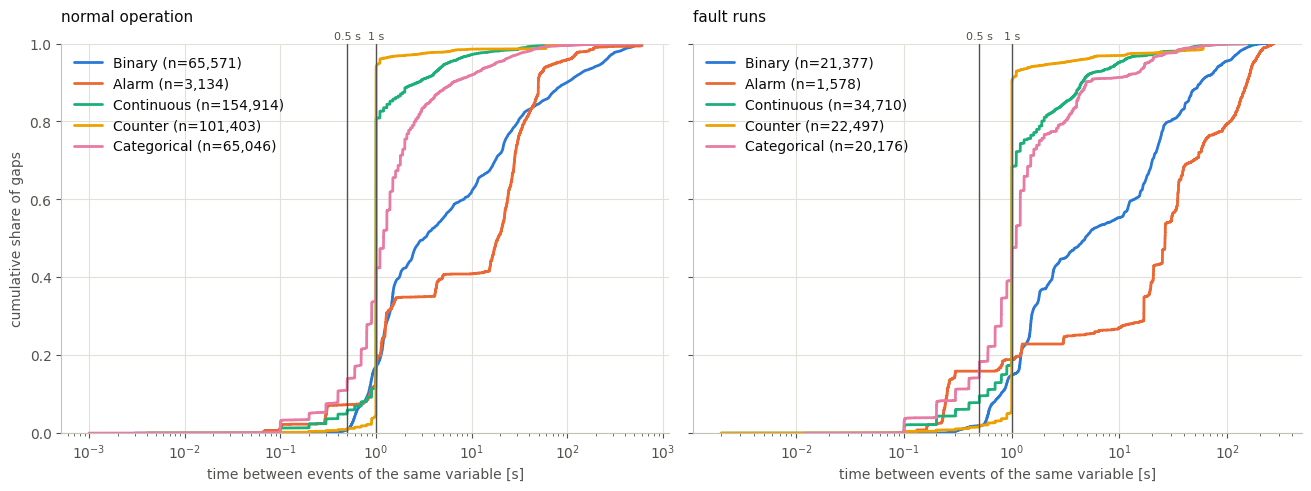

count    mean     std    min     5%     50%      95%      max
source   type                                                                         
dig_twin Alarm          1578.0  50.420  59.711  0.098  0.232  26.500  174.562  272.574
         Binary        21377.0  20.309  32.260  0.082  0.606   4.802   92.628  259.291
         Categorical   20176.0   3.636   9.473  0.012  0.200   1.101   17.638  153.874
         Continuous    34710.0   3.005   9.142  0.002  0.300   1.001    9.608  177.220
         Counter       22497.0   2.411   8.550  0.002  0.923   1.001    2.794  142.400
real_op  Alarm          3134.0  27.232  56.649  0.049  0.303  18.842   75.880  600.300
         Binary        65571.0  35.207  83.203  0.003  0.616   3.183  233.474  599.866
         Categorical   65046.0   4.687  22.930  0.001  0.201   1.200   17.899  599.982
         Continuous   154914.0   2.767  15.940  0.004  0.500   1.000    5.604  599.926
         Counter      101403.0   2.298  14.705  0.004  0.999   1.000    1.099  598.762

In [30]:
# figure 6: time between consecutive events of the same variable
ordered = events.sort_values(['recording_id', 'node', 'time_s'])
gaps = ordered.assign(gap_s=ordered.groupby(['recording_id', 'node']).time_s.diff()).dropna(subset=['gap_s'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, layout='constrained')
for ax, source in zip(axes, ['real_op', 'dig_twin']):
    for t in pp.VARIABLE_TYPES:
        values = gaps.loc[(gaps.source == source) & (gaps.type == t), 'gap_s']
        if len(values):
            ax.ecdf(values, color=ev.TYPE_COLORS[t], label=f'{t} (n={len(values):,})')
    for dt in CANDIDATES:
        ax.axvline(dt, color=ev.INK['secondary'], linewidth=1)
        ax.text(dt, 1.01, f'{dt:g} s', transform=ax.get_xaxis_transform(), ha='center', fontsize=8, color=ev.INK['secondary'])
    ax.set_xscale('log')
    ax.set_xlabel('time between events of the same variable [s]')
    ax.set_title(ev.SOURCE_LABELS[source], pad=16)
    ax.legend(loc='upper left')
axes[0].set_ylabel('cumulative share of gaps')
ev.save_figure(fig, '01_inter_event_gaps')
plt.show()

gaps.groupby(['source', 'type']).gap_s.describe(percentiles=[0.05, 0.5, 0.95]).round(3)

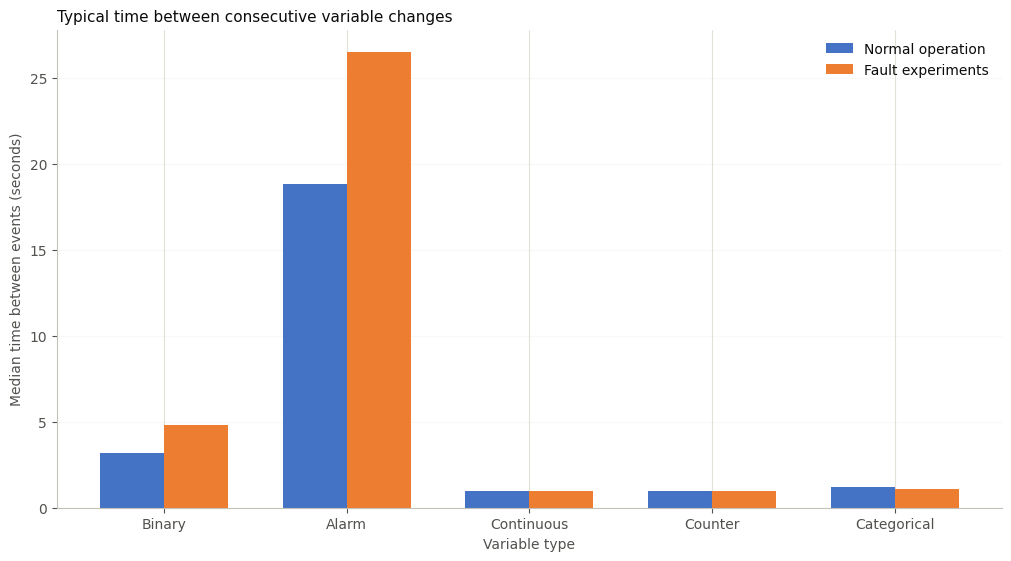

source,dig_twin,real_op
type,,
Binary,4.8,3.18
Alarm,26.5,18.84
Continuous,1.0,1.00
Counter,1.0,1.00
Categorical,1.1,1.20


In [42]:
# Figure 6: Typical time between consecutive events of the same variable

ordered = events.sort_values(['recording_id', 'node', 'time_s'])

gaps = (
    ordered.assign(
        gap_s=ordered.groupby(['recording_id', 'node']).time_s.diff()
    )
    .dropna(subset=['gap_s'])
)

# Calculate median time between events
summary = (
    gaps.groupby(['type', 'source'])['gap_s']
    .median()
    .unstack()
    .reindex(pp.VARIABLE_TYPES)
)

fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')

x = np.arange(len(summary))
width = 0.35

ax.bar(
    x - width / 2,
    summary['real_op'],
    width,
    label='Normal operation',
    color='#4472C4'
)

ax.bar(
    x + width / 2,
    summary['dig_twin'],
    width,
    label='Fault experiments',
    color='#ED7D31'
)

ax.set_xticks(x)
ax.set_xticklabels(summary.index)

ax.set_ylabel('Median time between events (seconds)')
ax.set_xlabel('Variable type')
ax.set_title('Typical time between consecutive variable changes')

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

ev.save_figure(fig, '01_inter_event_gaps')
plt.show()

display(summary.round(2))

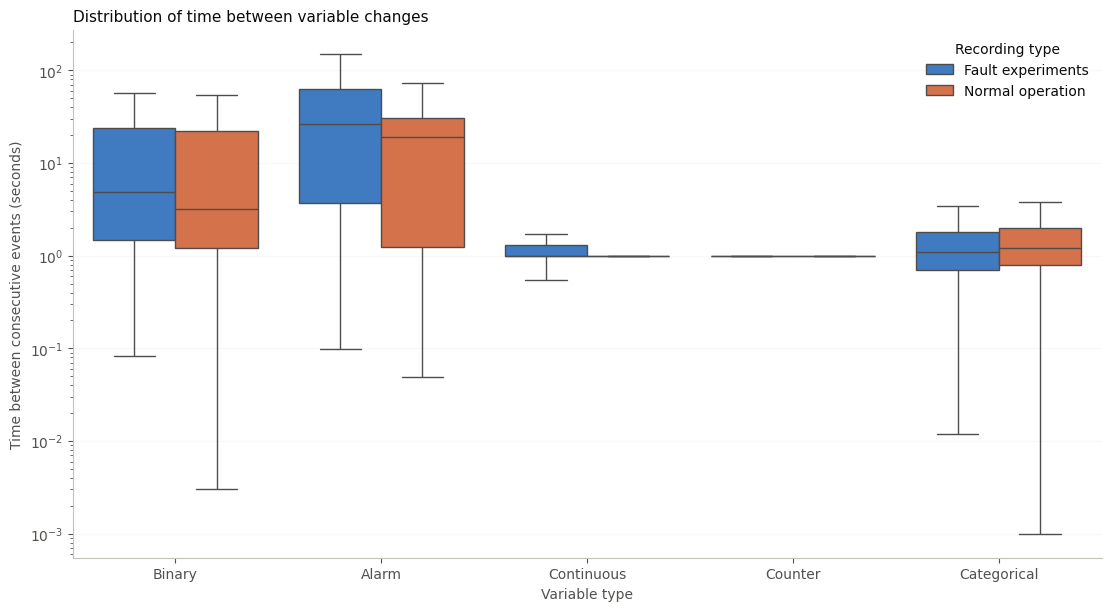

In [41]:
# Figure 6: Distribution of time between consecutive events

import matplotlib.pyplot as plt
import seaborn as sns

ordered = events.sort_values(
    ['recording_id', 'node', 'time_s']
)

gaps = (
    ordered.assign(
        gap_s=ordered.groupby(
            ['recording_id', 'node']
        ).time_s.diff()
    )
    .dropna(subset=['gap_s'])
)

# Keep positive intervals for log scale
plot_data = gaps[gaps['gap_s'] > 0].copy()

plot_data['source_label'] = plot_data['source'].map({
    'real_op': 'Normal operation',
    'dig_twin': 'Fault experiments'
})

fig, ax = plt.subplots(
    figsize=(11, 6),
    layout='constrained'
)

sns.boxplot(
    data=plot_data,
    x='type',
    y='gap_s',
    hue='source_label',
    order=pp.VARIABLE_TYPES,
    showfliers=False,
    ax=ax
)

ax.set_yscale('log')

ax.set_xlabel('Variable type')
ax.set_ylabel('Time between consecutive events (seconds)')
ax.set_title(
    'Distribution of time between variable changes'
)

ax.legend(
    title='Recording type',
    frameon=False
)

ax.grid(
    axis='y',
    alpha=0.2
)

ev.save_figure(
    fig,
    '01_inter_event_gaps'
)

plt.show()

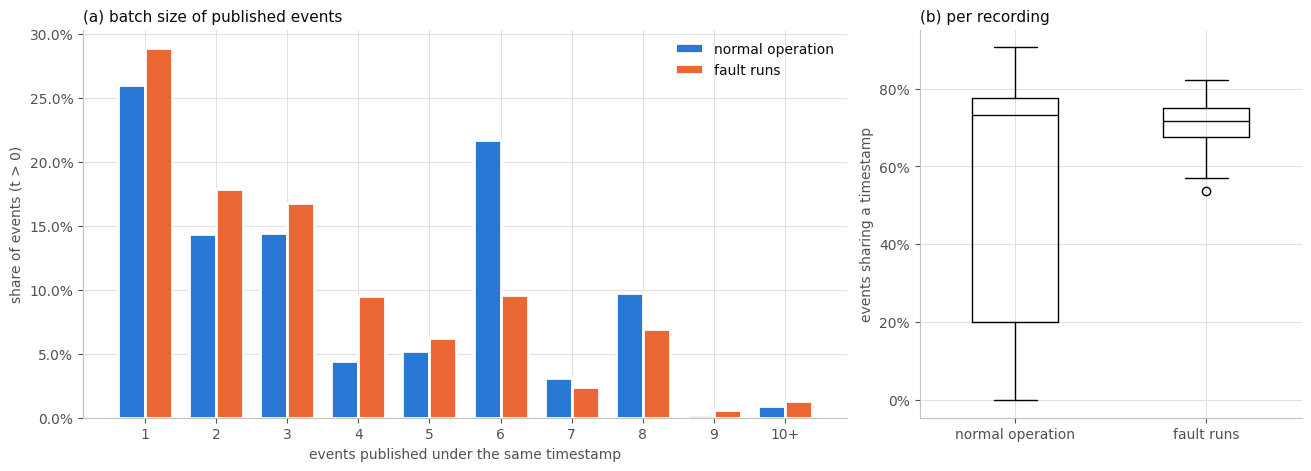

In [31]:
# figure 7: several variables published under one timestamp (opc ua batches)
batches = data.timestamp_batches(events)
batches['batch_size'] = batches.n_events.clip(upper=10)
share = batches.groupby(['batch_size', 'source']).n_events.sum().unstack('source').reindex(range(1, 11)).fillna(0)
share = share / share.sum()

per_recording = (
    events[events.time_s > 0]
    .assign(shared=lambda d: d.duplicated(['recording_id', 'time_s'], keep=False))
    .groupby('recording_id')
    .agg(source=('source', 'first'), share_shared=('shared', 'mean'))
)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [2, 1]}, layout='constrained')
width = 0.38
for k, source in enumerate(['real_op', 'dig_twin']):
    ax_a.bar(share.index + (k - 0.5) * width, share[source], width=width, color=ev.SOURCE_COLORS[source],
             edgecolor=ev.INK['surface'], linewidth=2, label=ev.SOURCE_LABELS[source])
ax_a.set_xticks(range(1, 11), [str(i) for i in range(1, 10)] + ['10+'])
ax_a.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_a.set_xlabel('events published under the same timestamp')
ax_a.set_ylabel('share of events (t > 0)')
ax_a.set_title('(a) batch size of published events')
ax_a.legend()

sources = ['real_op', 'dig_twin']
ax_b.boxplot([per_recording.loc[per_recording.source == s, 'share_shared'] for s in sources],
             widths=0.45, medianprops={'color': ev.INK['primary']})
ax_b.set_xticks([1, 2], [ev.SOURCE_LABELS[s] for s in sources])
ax_b.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_b.set_ylabel('events sharing a timestamp')
ax_b.set_title('(b) per recording')
ev.save_figure(fig, '01_timestamp_batches')
plt.show()

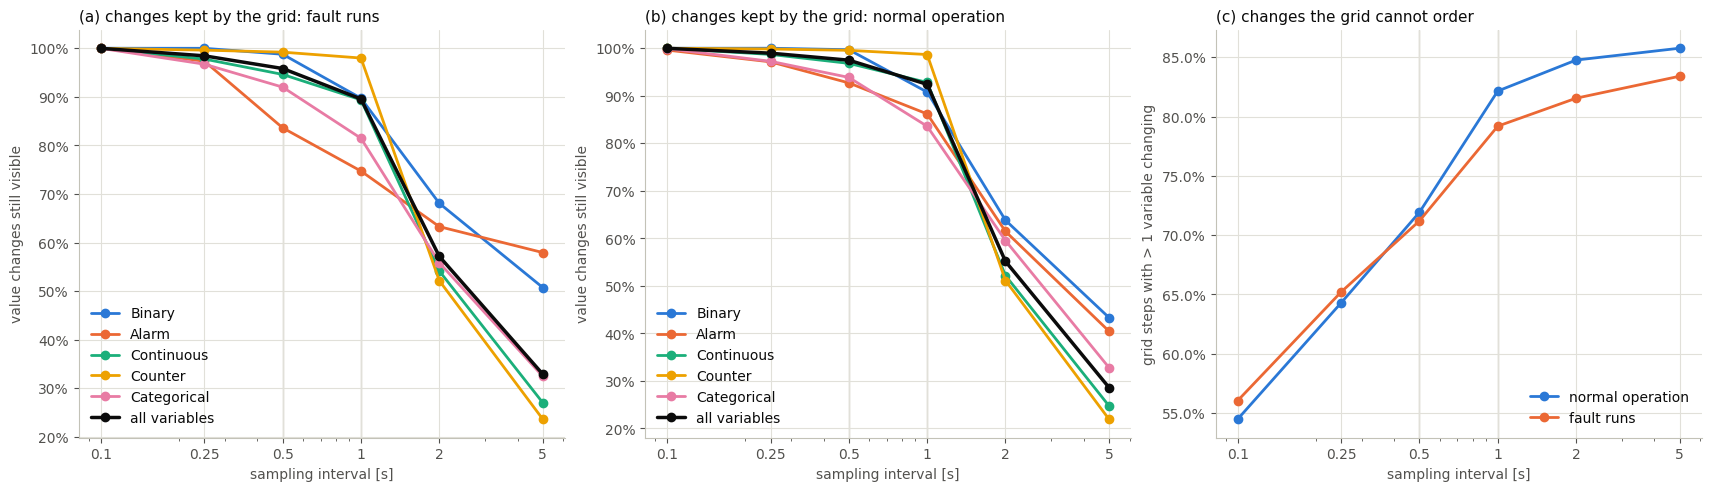

interval_s               0.10   0.25   0.50   1.00   2.00   5.00
source   variable_type                                          
dig_twin ALL            1.000  0.984  0.958  0.896  0.572  0.329
         Alarm          1.000  0.973  0.836  0.747  0.633  0.579
         Binary         1.000  1.000  0.988  0.897  0.681  0.507
         Categorical    1.000  0.967  0.920  0.815  0.558  0.325
         Continuous     1.000  0.978  0.946  0.894  0.542  0.270
         Counter        1.000  0.996  0.992  0.980  0.522  0.236
real_op  ALL            1.000  0.990  0.975  0.924  0.552  0.286
         Alarm          0.996  0.971  0.927  0.862  0.615  0.405
         Binary         1.000  1.000  0.997  0.908  0.638  0.433
         Categorical    0.999  0.972  0.939  0.836  0.595  0.328
         Continuous     1.000  0.987  0.968  0.928  0.522  0.248
         Counter        1.000  0.998  0.996  0.987  0.511  0.220

In [32]:
# figure 8: what a regular grid keeps, per sampling interval
sensitivity = pp.sampling_sensitivity(events, INTERVALS)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout='constrained')
for ax, source, label in zip(axes[:2], ['dig_twin', 'real_op'], ['(a)', '(b)']):
    rows = sensitivity[sensitivity.source == source]
    for t in pp.VARIABLE_TYPES:
        line = rows[rows.variable_type == t]
        if len(line):
            ax.plot(line.interval_s, line.transition_retention, marker='o', color=ev.TYPE_COLORS[t], label=t)
    total = rows[rows.variable_type == 'ALL']
    ax.plot(total.interval_s, total.transition_retention, marker='o', color=ev.INK['primary'], linewidth=2.5, label='all variables')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylabel('value changes still visible')
    ax.set_title(f'{label} changes kept by the grid: {ev.SOURCE_LABELS[source]}')
    ax.legend(loc='lower left')

ax = axes[2]
for source in ['real_op', 'dig_twin']:
    total = sensitivity[(sensitivity.source == source) & (sensitivity.variable_type == 'ALL')]
    ax.plot(total.interval_s, total.multi_change_step_fraction, marker='o', color=ev.SOURCE_COLORS[source],
            label=ev.SOURCE_LABELS[source])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel('grid steps with > 1 variable changing')
ax.set_title('(c) changes the grid cannot order')
ax.legend(loc='lower right')

for ax in axes:
    for dt in CANDIDATES:
        ax.axvline(dt, color=ev.INK['axis'], linewidth=1, zorder=0)
    ax.set_xscale('log')
    ax.set_xticks(INTERVALS, [f'{d:g}' for d in INTERVALS])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('sampling interval [s]')
ev.save_figure(fig, '01_sampling_sensitivity')
plt.show()

sensitivity.pivot_table(index=['source', 'variable_type'], columns='interval_s', values='transition_retention').round(3)

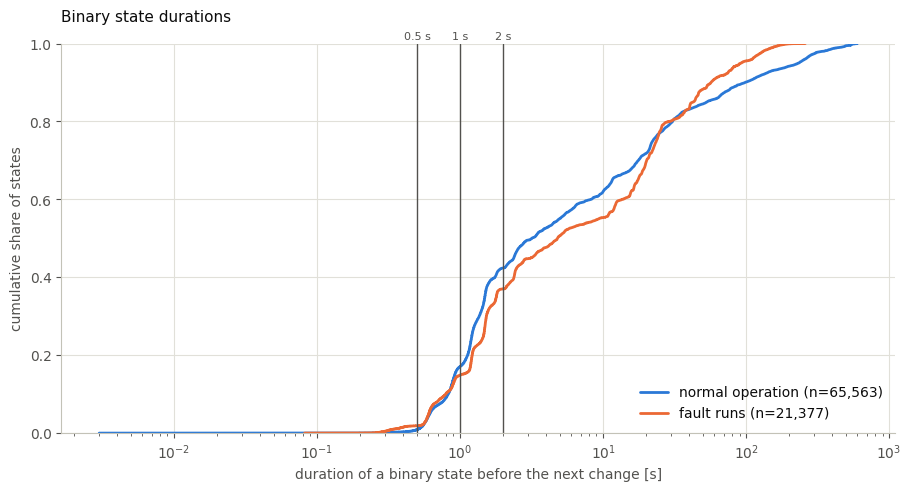

,0.25,0.50,1.00,2.00,5.00
source,,,,,
dig_twin,0.001,0.019,0.149,0.370,0.507
real_op,0.001,0.009,0.171,0.424,0.551


In [33]:
# figure 9: how long binary states last (short pulses vanish on a coarse grid)
binary_states = data.state_durations(events, types=('Binary',))
complete = binary_states[~binary_states.censored & (binary_states.duration_s > 0)]

fig, ax = plt.subplots(figsize=(9, 4.8), layout='constrained')
for source in ['real_op', 'dig_twin']:
    values = complete.loc[complete.source == source, 'duration_s']
    ax.ecdf(values, color=ev.SOURCE_COLORS[source], label=f'{ev.SOURCE_LABELS[source]} (n={len(values):,})')
for dt in [0.5, 1.0, 2.0]:
    ax.axvline(dt, color=ev.INK['secondary'], linewidth=1)
    ax.text(dt, 1.01, f'{dt:g} s', transform=ax.get_xaxis_transform(), ha='center', fontsize=8, color=ev.INK['secondary'])
ax.set_xscale('log')
ax.set_xlabel('duration of a binary state before the next change [s]')
ax.set_ylabel('cumulative share of states')
ax.set_title('Binary state durations', pad=16)
ax.legend(loc='lower right')
ev.save_figure(fig, '01_binary_state_durations')
plt.show()

# share of binary states shorter than each interval
pd.DataFrame({dt: complete.groupby('source').duration_s.apply(lambda d: (d < dt).mean()) for dt in [0.25, 0.5, 1.0, 2.0, 5.0]}).round(3)

**Findings.**
- About 70% of events after t = 0 share their timestamp with another variable (per-recording median about 73% in normal operation, 71% in fault runs; figure 7b). The publish order inside a batch carries no causal information.
- Continuous and Counter variables are published about once per second (median gap 1.0 s). A grid finer than 1 s adds rows but few new values for them.
- Changes kept in fault runs: 96% at 0.5 s, 90% at 1 s, 57% at 2 s. Alarms suffer most: 84% at 0.5 s and 75% at 1 s.
- Binary states: 15% (fault runs) and 17% (normal) last less than 1 s; only about 2% and 1% last less than 0.5 s. A 1 s grid loses a noticeable share of short pulses, a 0.5 s grid almost none.
- Figure 8c: even at 0.1 s, 55–56% of grid steps with a change contain more than one changing variable; at 1 s it is about 80%. Lag-0 (contemporaneous) links cannot be oriented from timestamps.
- *Thesis note:* 0.5 s is the safer default for binary data; 1 s halves the number of rows. Stage 1 compares both. Contemporaneous links stay unoriented in Stage 3.

## 7. Fault timing: annotations vs observed changes

`causes.json` gives five timestamps per run. We check how they relate to the moments the manipulated variables and the expected alarms actually change in the data.

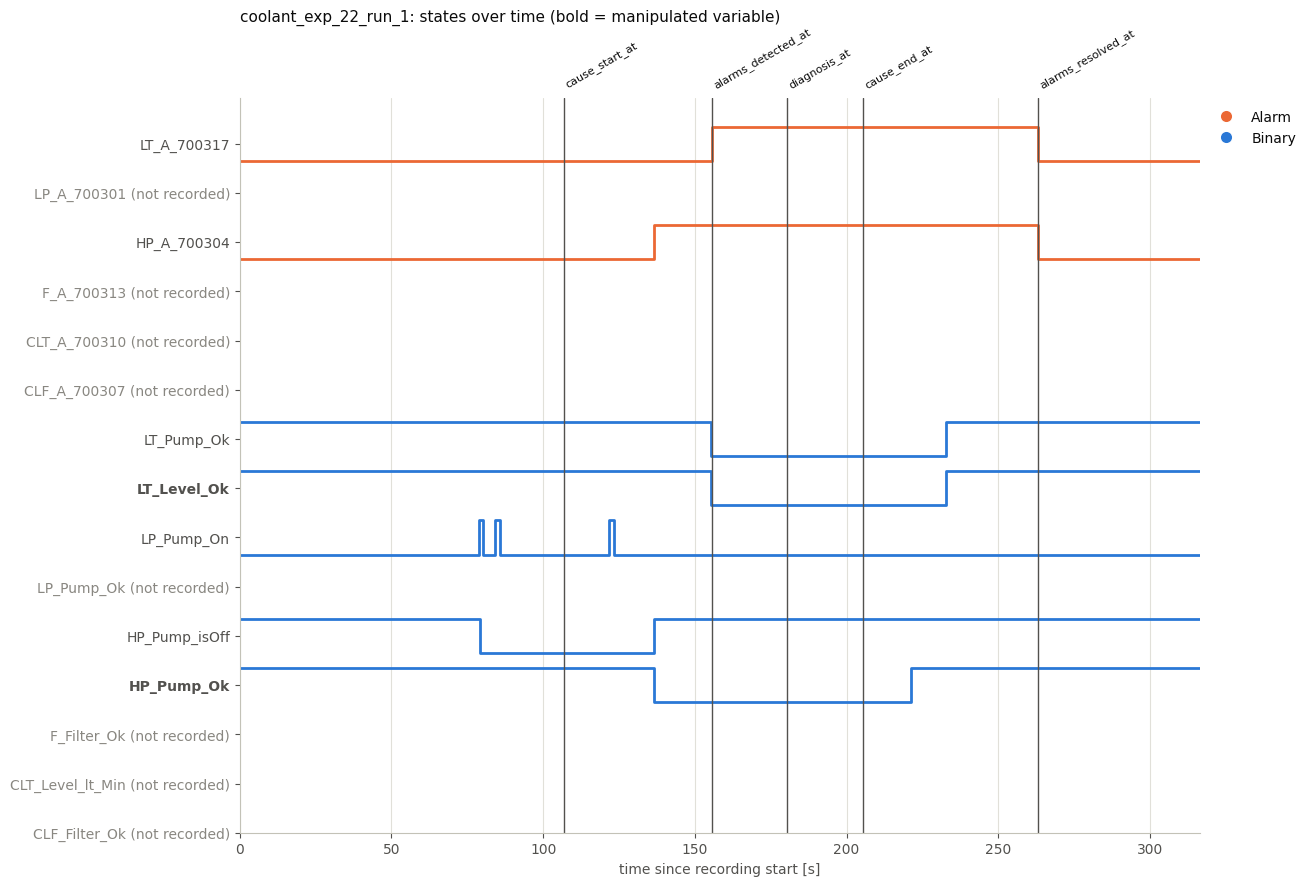

In [34]:
# figure 10: one fault run as a timeline of all subsystem variables
EXAMPLE_RUN = 'coolant_exp_22_run_1'
run = runs.set_index('recording_id').loc[EXAMPLE_RUN]
truth = experiments.set_index(['subsystem', 'experiment_id']).loc[(run.subsystem, run.experiment_id)]
# alarms last, so they are drawn at the top
nodes = sorted(graphs[run.subsystem].nodes, key=lambda n: (types.get(n) == 'Alarm', n))
run_events = events[events.recording_id == EXAMPLE_RUN]
t_end = run_events.time_s.max()

fig, ax = plt.subplots(figsize=(13, 0.45 * len(nodes) + 2), layout='constrained')
for i, node in enumerate(nodes):
    e = run_events[run_events.node == node].sort_values('time_s')
    if e.empty or e.value_num.isna().all():
        continue
    v = e.value_num.to_numpy(dtype=float)
    span = np.nanmax(v) - np.nanmin(v)
    # scale every variable to 0..1 so the rows do not overlap
    v = (v - np.nanmin(v)) / span if span > 0 else np.zeros_like(v)
    ax.step(np.append(e.time_s, t_end), i + 0.7 * np.append(v, v[-1]), where='post',
            color=ev.TYPE_COLORS.get(types[node], ev.INK['muted']))
# variables without any event in this run are marked as not recorded
recorded = set(run_events.node)
ax.set_yticks(np.arange(len(nodes)) + 0.35, [n if n in recorded else f'{n} (not recorded)' for n in nodes])
for tick, node in zip(ax.get_yticklabels(), nodes):
    if node in truth.manipulated_vars:
        tick.set_fontweight('bold')
    if node not in recorded:
        tick.set_color(ev.INK['muted'])
for name in data.CAUSE_TIMESTAMPS:
    ax.axvline(run[name], color=ev.INK['secondary'], linewidth=1)
    ax.text(run[name], 1.01, name, transform=ax.get_xaxis_transform(), rotation=30, ha='left', va='bottom', fontsize=8)
ax.set_xlim(0, t_end)
ax.grid(axis='y', visible=False)
ax.set_xlabel('time since recording start [s]')
ax.legend(handles=ev.type_legend_handles(sorted({types[n] for n in nodes if n in types})),
          loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.set_title(f'{EXAMPLE_RUN}: states over time (bold = manipulated variable)', pad=55)
ev.save_figure(fig, '01_fault_timeline_example')
plt.show()

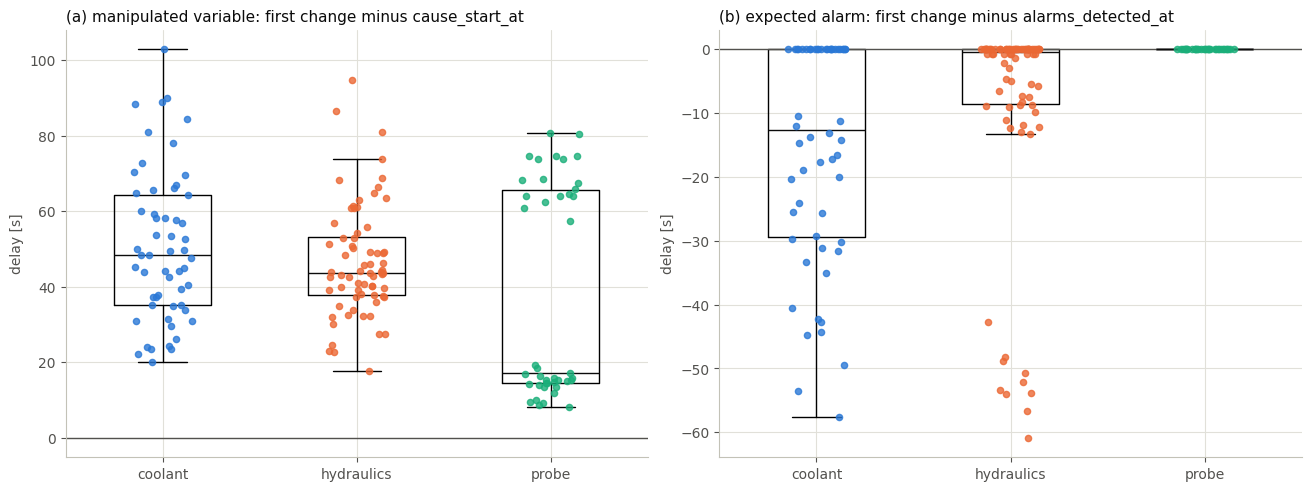

,pairs,share_changing_after_start,median_delay_s,max_delay_s
subsystem,,,,
coolant,56,1.0,48.37,102.89
hydraulics,68,1.0,43.74,94.80
probe,42,1.0,17.10,80.60


In [35]:
# figure 11: delays between annotated timestamps and observed first changes
cause_changes = data.fault_variable_changes(events, runs, experiments, column='manipulated_vars')
alarm_changes = data.fault_variable_changes(events, runs, experiments, column='alarms')
alarm_changes['delay_from_alarms_detected_s'] = alarm_changes.first_change_after_start_s - alarm_changes.alarms_detected_at
ev.save_table(cause_changes, '01_run_validity')

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
rng = np.random.default_rng(0)
panels = [
    (ax_a, cause_changes, 'delay_from_cause_start_s', '(a) manipulated variable: first change minus cause_start_at'),
    (ax_b, alarm_changes, 'delay_from_alarms_detected_s', '(b) expected alarm: first change minus alarms_detected_at'),
]
for ax, table, col, title in panels:
    values_by_subsystem = [table.loc[table.subsystem == s, col].dropna().to_numpy() for s in data.SUBSYSTEMS]
    ax.boxplot(values_by_subsystem, widths=0.5, showfliers=False, medianprops={'color': ev.INK['primary']})
    # one dot per run and variable
    for k, (s, values) in enumerate(zip(data.SUBSYSTEMS, values_by_subsystem), start=1):
        ax.scatter(k + rng.uniform(-0.15, 0.15, len(values)), values, s=20, color=ev.SUBSYSTEM_COLORS[s], alpha=0.8, zorder=3)
    ax.axhline(0, color=ev.INK['secondary'], linewidth=1)
    ax.set_xticks(range(1, 4), data.SUBSYSTEMS)
    ax.set_ylabel('delay [s]')
    ax.set_title(title)
ev.save_figure(fig, '01_annotation_delays')
plt.show()

cause_changes.groupby('subsystem').agg(
    pairs=('variable', 'size'),
    share_changing_after_start=('changes_after_start', 'mean'),
    median_delay_s=('delay_from_cause_start_s', 'median'),
    max_delay_s=('delay_from_cause_start_s', 'max'),
).round(2)

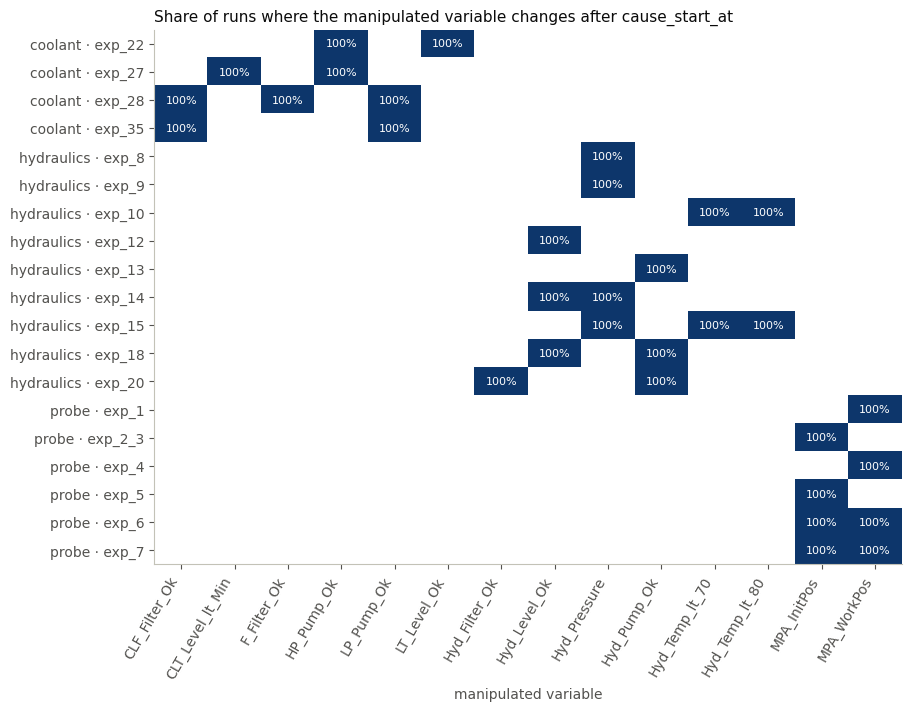

,recording_id,variable,initial_value,n_changes,n_changes_before_start


In [36]:
# figure 12: share of runs in which each manipulated variable changes after cause_start_at
validity = cause_changes.pivot_table(index=['subsystem', 'experiment_id'], columns='variable',
                                     values='changes_after_start', aggfunc='mean')
validity = validity.reindex(index=pd.MultiIndex.from_frame(experiments[['subsystem', 'experiment_id']]), columns=cause_order)
values = validity.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
cmap = ev.sequential_cmap()
cmap.set_bad(ev.INK['surface'])
ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=0, vmax=1, aspect='auto')
for (i, j), v in np.ndenumerate(values):
    if not np.isnan(v):
        ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8,
                color=ev.INK['surface'] if v > 0.55 else ev.INK['primary'])
ax.set_xticks(range(len(cause_order)), cause_order, rotation=60, ha='right')
ax.set_yticks(range(len(validity)), [f'{s} · {e}' for s, e in validity.index])
ax.grid(False)
ax.set_xlabel('manipulated variable')
ax.set_title('Share of runs where the manipulated variable changes after cause_start_at')
ev.save_figure(fig, '01_run_validity')
plt.show()

# runs where a manipulated variable never changes after cause_start_at
cause_changes.loc[~cause_changes.changes_after_start,
                  ['recording_id', 'variable', 'initial_value', 'n_changes', 'n_changes_before_start']]

**Findings.**
- **Effect before cause in the log (figure 10).** `HP_Pump_isOff = True` is published at 136.387 s, 0.16 s *before* its expert cause `HP_Pump_Ok = False` at 136.549 s. `LT_Level_Ok` and `LT_Pump_Ok` share one timestamp (155.292 s). This is a concrete example for the thesis of why timestamps cannot orient short-lag links.
- `cause_start_at` comes before the first visible change of every manipulated variable: median delay 48 s (coolant), 44 s (hydraulics), 17 s (probe), never negative. It marks when the simulated degradation starts, not when the variable visibly changes.
- `alarms_detected_at` equals the onset of the **last** expected alarm in all 100 runs (checked to within 10 ms). It equals the first alarm in only 48 runs, mostly single-alarm scenarios. Every expected alarm fires in every run.
- Figure 12 is 100% everywhere: every manipulated variable changes after `cause_start_at` in every run, so no run has to be excluded for an invisible manipulation. For probe this is weak evidence, because the probe causes also change *before* `cause_start_at` in every probe run (normal cycling).
- 3 hydraulics runs (exp_12 run_1, exp_14 runs 2 and 4) have `alarms_resolved_at` only about 0.03 s after `alarms_detected_at`, before `diagnosis_at`. This explains the one failed metadata check. It is a property of the annotations, not a loading error, so `alarms_resolved_at` should not be used as the end of a fault.
- *Thesis note:* for RCA, a window anchored on the first observed alarm is label-free, because alarms are visible at run time. A window anchored on `cause_start_at` uses annotation knowledge. We decide this explicitly in Stage 5.

## 8. Expert causal graphs

The expert graph is the reference for Stage 3. Agreement with it is agreement with expert knowledge, not proof of the true causal structure.

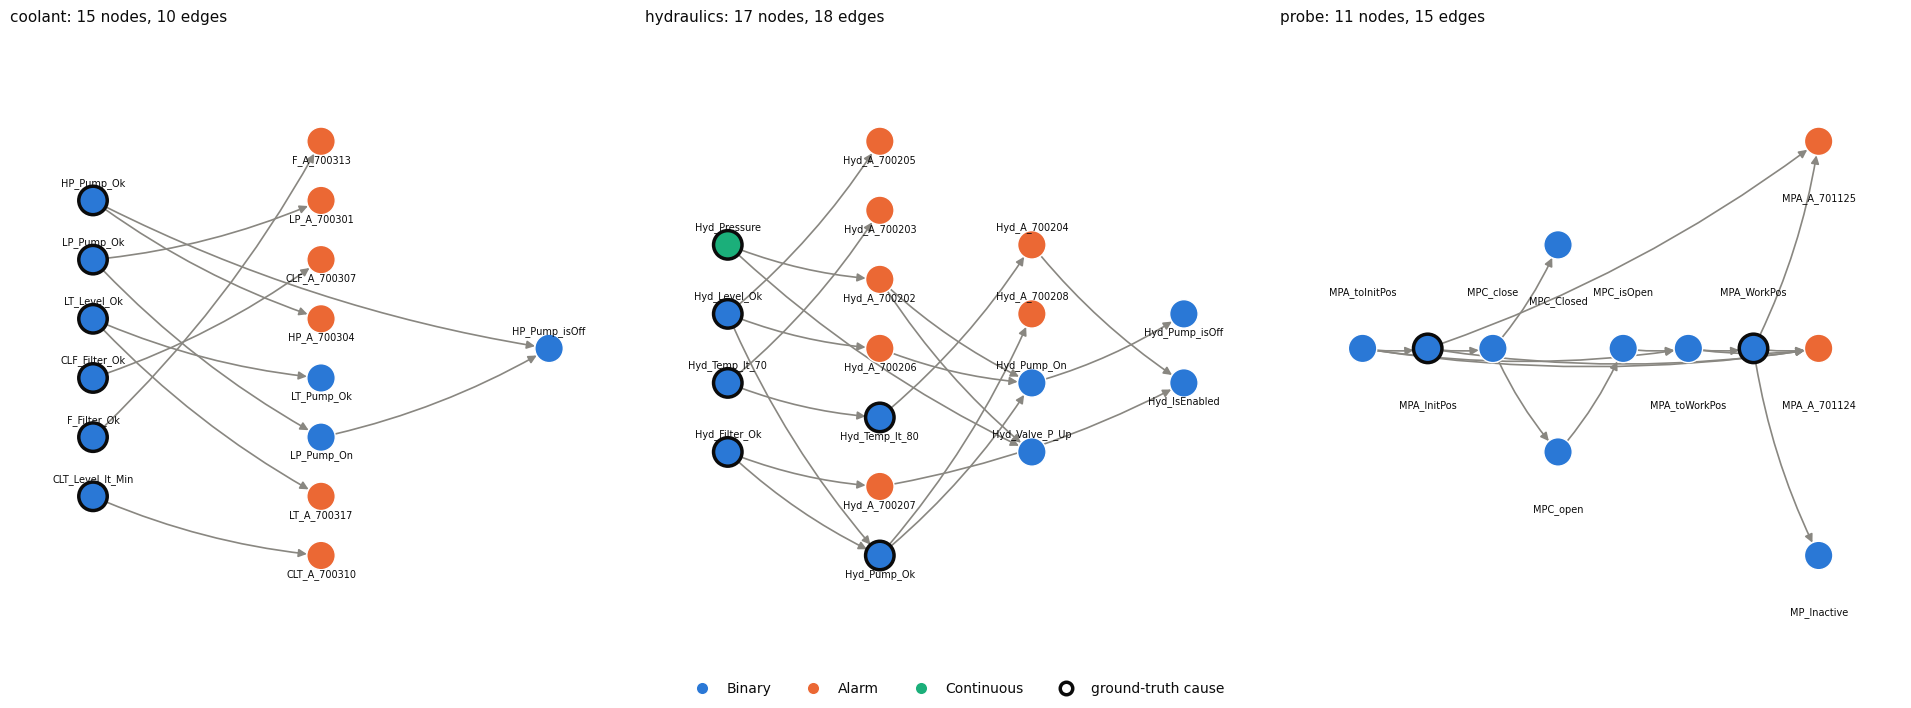

In [37]:
# figure 13: expert subsystem graphs (dark ring = ground-truth cause in some scenario)
fig, axes = plt.subplots(1, 3, figsize=(19, 7), layout='constrained')
for ax, (subsystem, graph) in zip(axes, graphs.items()):
    causes = set(experiments.loc[experiments.subsystem == subsystem, 'manipulated_vars'].explode())
    ev.draw_graph(graph, ax, node_types=types, highlight=causes,
                  title=f'{subsystem}: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges')
present = sorted({types[n] for g in graphs.values() for n in g.nodes if n in types}, key=pp.VARIABLE_TYPES.index)
fig.legend(handles=ev.type_legend_handles(present, highlight_label='ground-truth cause'),
           loc='outside lower center', ncol=len(present) + 1)
ev.save_figure(fig, '01_expert_subsystem_graphs')
plt.show()

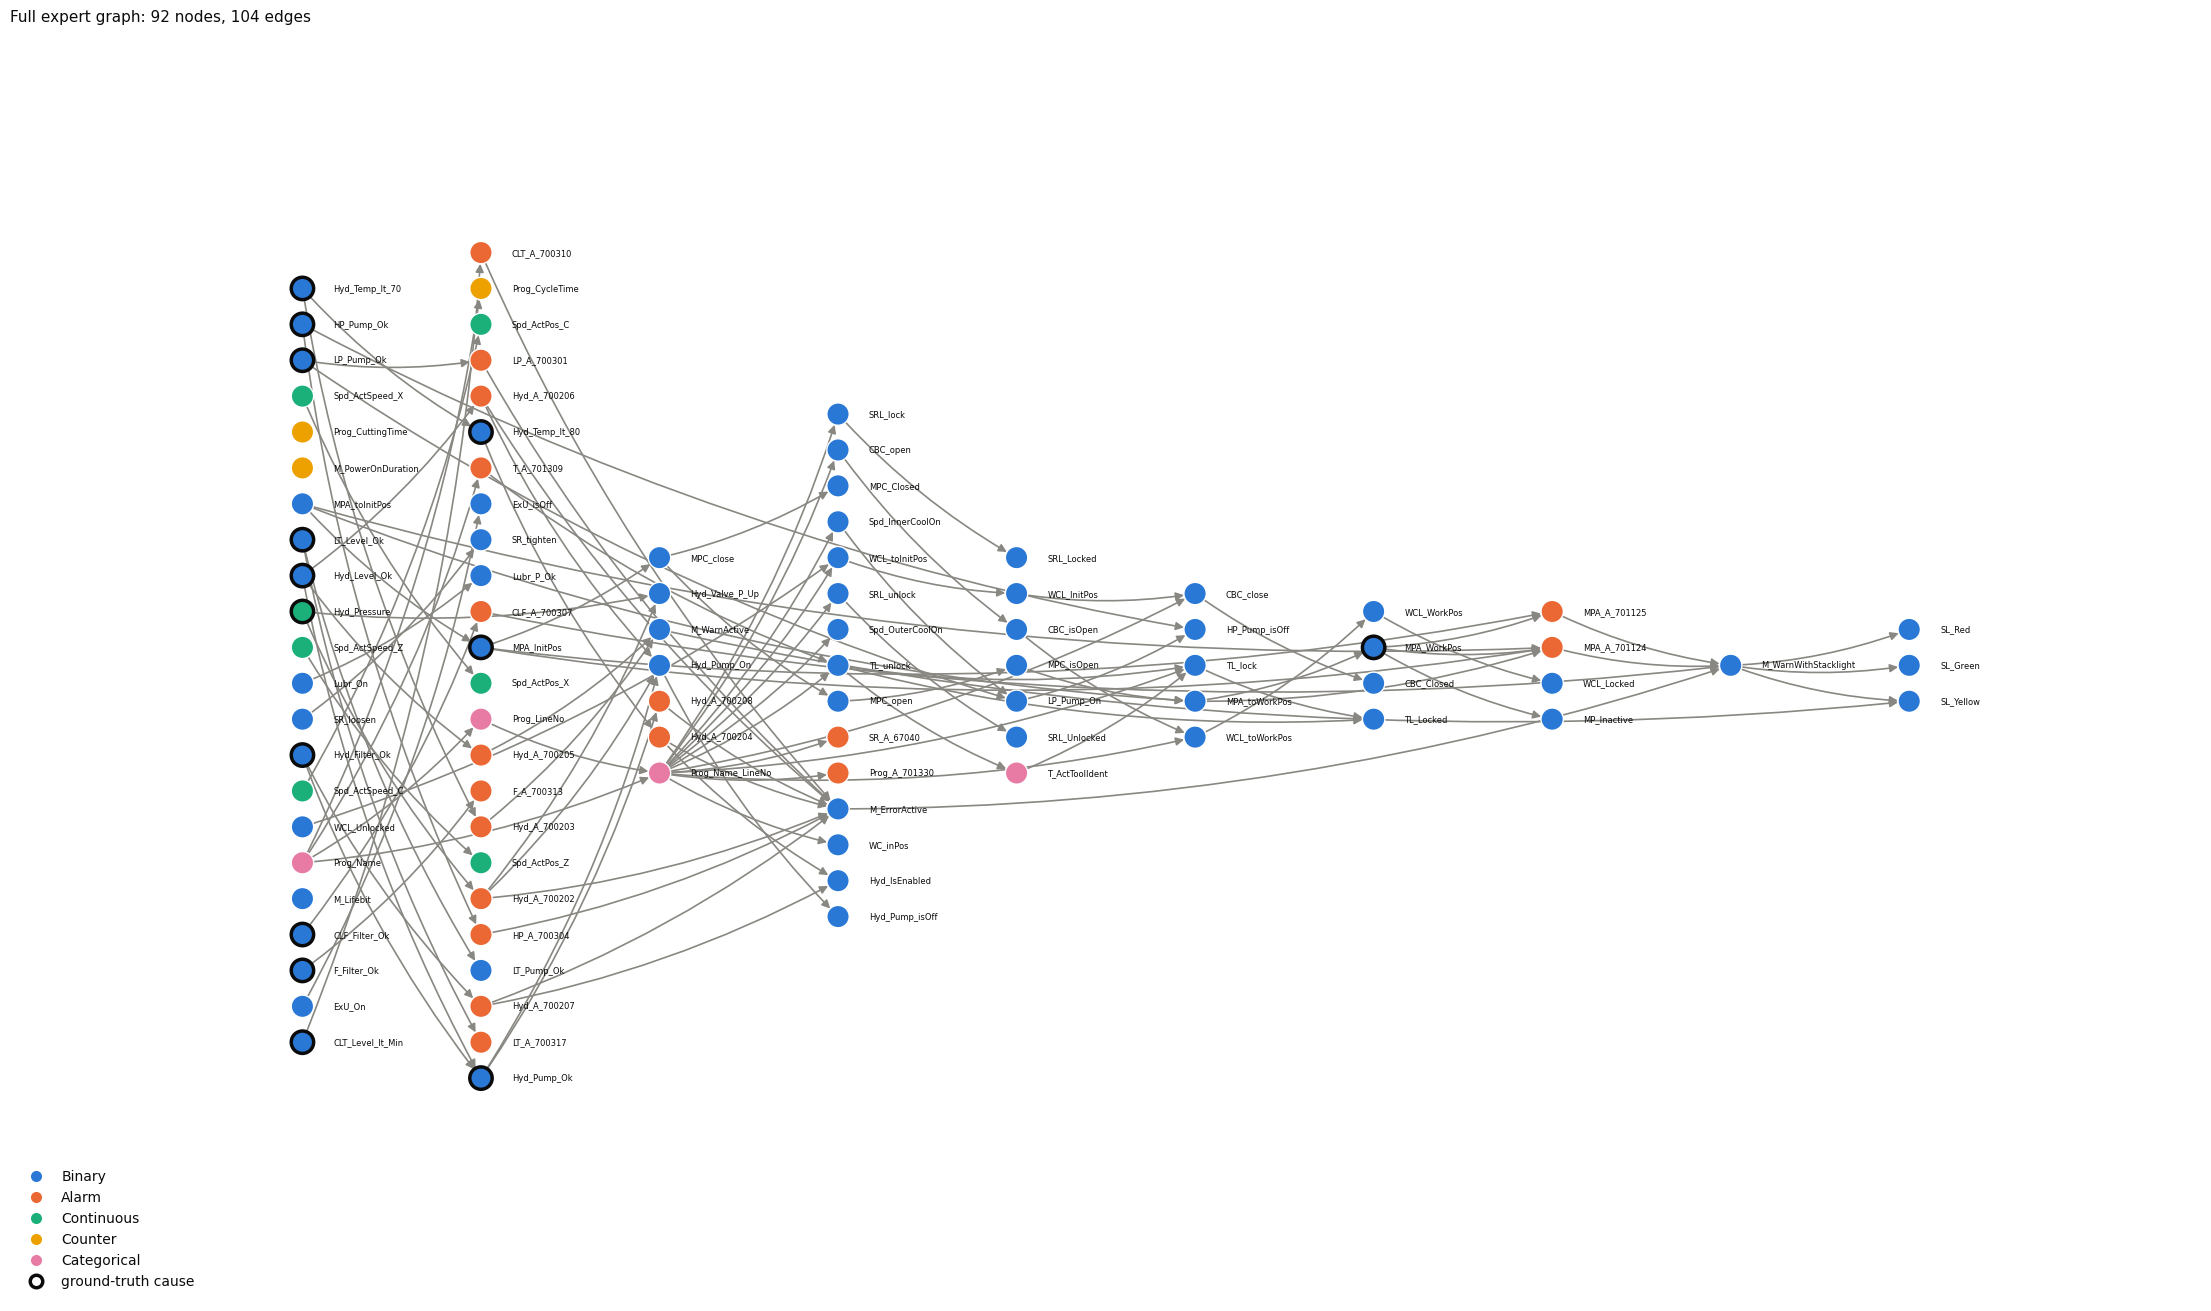

In [38]:
# figure 14: full expert graph of the machine
all_causes = set(experiments.manipulated_vars.explode())
fig, ax = plt.subplots(figsize=(22, 13), layout='constrained')
ev.draw_graph(full_graph, ax, node_types=types, highlight=all_causes, node_size=260, label_side='right', font_size=6,
              title=f'Full expert graph: {full_graph.number_of_nodes()} nodes, {full_graph.number_of_edges()} edges')
present = sorted({types[n] for n in full_graph.nodes if n in types}, key=pp.VARIABLE_TYPES.index)
ax.legend(handles=ev.type_legend_handles(present, highlight_label='ground-truth cause'), loc='lower left')
ev.save_figure(fig, '01_expert_full_graph')
plt.show()

In [39]:
# structure of each expert graph
def describe_graph(name, graph):
    simple = nx.DiGraph(graph)
    return {
        'graph': name,
        'nodes': graph.number_of_nodes(),
        'edges': graph.number_of_edges(),
        'duplicate_edges': graph.number_of_edges() - simple.number_of_edges(),
        'acyclic': nx.is_directed_acyclic_graph(simple),
        'isolated_nodes': sorted(nx.isolates(simple)),
        'source_nodes': sorted(n for n in simple if simple.in_degree(n) == 0 and simple.out_degree(n) > 0),
        'sink_nodes': sorted(n for n in simple if simple.out_degree(n) == 0 and simple.in_degree(n) > 0),
    }

pd.DataFrame([describe_graph('full', full_graph)] + [describe_graph(s, g) for s, g in graphs.items()])

,graph,nodes,edges,duplicate_edges,acyclic,isolated_nodes,source_nodes,sink_nodes
0,full,92,104,2,True,"[M_Lifebit, M_PowerOnDuration, Prog_CuttingTime]","[CLF_Filter_Ok, CLT_Level_lt_Min, ExU_On, F_Fi...","[CBC_Closed, ExU_isOff, F_A_700313, HP_Pump_is..."
1,coolant,15,10,0,True,[],"[CLF_Filter_Ok, CLT_Level_lt_Min, F_Filter_Ok,...","[CLF_A_700307, CLT_A_700310, F_A_700313, HP_A_..."
2,hydraulics,17,18,0,True,[],"[Hyd_Filter_Ok, Hyd_Level_Ok, Hyd_Pressure, Hy...","[Hyd_A_700203, Hyd_A_700205, Hyd_A_700208, Hyd..."
3,probe,11,15,0,True,[],[MPA_toInitPos],"[MPA_A_701124, MPA_A_701125, MPC_Closed, MP_In..."


**Findings.**
- All expert graphs (full and subsystems) are acyclic, so a static SCM over the expert graph is structurally possible in Stage 4. Feedback loops are not represented.
- The full graph has 2 duplicate edges (`Prog_Name_LineNo` → `CBC_close` / `CBC_open`) and 3 isolated nodes (`M_Lifebit`, `M_PowerOnDuration`, `Prog_CuttingTime`). Graph metrics must count each edge once.
- **Root causes are not always graph roots.** All 6 coolant causes are source nodes. In hydraulics, `Hyd_Pump_Ok` has parents (`Hyd_Filter_Ok`, `Hyd_Level_Ok`) and `Hyd_Temp_lt_80` has parent `Hyd_Temp_lt_70`. In probe, both causes have parents (`MPA_toInitPos` → `MPA_InitPos`, `MPA_toWorkPos` → `MPA_WorkPos`).
- *Thesis note:* a rule like *pick the most upstream anomalous variable* would systematically miss the probe causes. This motivates SCM-based attribution in Stage 5, where an intervened variable is found because its own mechanism breaks, not because of its position in the graph.

## 9. Summary: what is suitable for the next stages

| Question | Finding | Consequence |
|---|---|---|
| Metadata consistent? | 50 of 51 checks pass; all README counts reproduced | the one failure is 3 runs with near-instant alarm resolution (annotation property) |
| Variable types | coolant and probe Binary/Alarm only; hydraulics has 1 continuous variable | discrete CI test in Stage 2; no ParCorr on binary states |
| Fault variables in normal data | 11 of 12 coolant/hydraulics causes never change | discovery must include fault runs; regime pooling must be justified (Stage 2) |
| Batched timestamps | about 70% of events share a timestamp; effects can be logged before causes | lag-0 links stay unoriented (Stage 3) |
| Sampling interval | 0.5 s keeps 96% of changes, 1 s keeps 90%; 15% of binary states last < 1 s | compare 0.5 s and 1 s in Stage 1 |
| Annotation timing | `cause_start_at` 17–48 s (median) before the visible change; `alarms_detected_at` = last alarm | RCA window definition (Stage 5) |
| Manipulation visible? | yes, in every run | no run excluded; probe evidence is weak |
| Causes vs graph roots | 4 of 14 causes have expert parents | SCM-based attribution, not *most upstream* (Stage 5) |

**Suggested first subsystem for Stage 2:** coolant. It is small (15 nodes, 10 edges), every cause is a source node, and it has 25 runs over 4 scenarios, but it is all binary and only 4 variables vary in normal operation. Hydraulics has more runs (41) and one continuous variable. We decide in the Stage 2 plan.

**Saved tables:** `01_metadata_checks.csv`, `01_experiments.csv`, `01_variable_suitability.csv`, `01_run_validity.csv`.